n   Analytical   Numerical
1 2.4674 2.46735
2 9.8696 9.8688
3 22.20661 22.20254


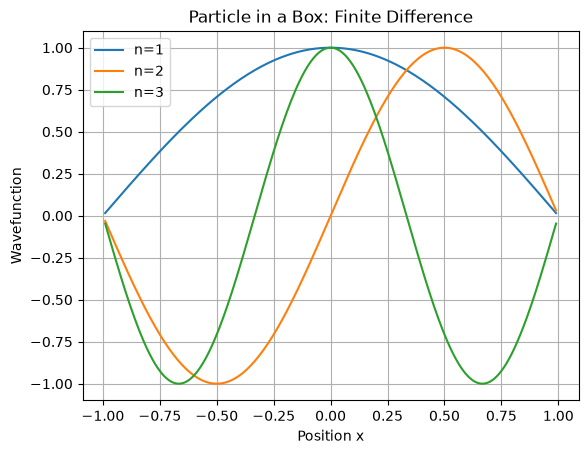

In [2]:

import numpy as np
import matplotlib.pyplot as plt

a = 1.0
N = 200
dx = 2*a/(N+1)
x = np.linspace(-a+dx, a-dx, N)

# Hamiltonian matrix
H = np.diag(np.full(N, 2/dx**2))
H += np.diag(np.full(N-1, -1/dx**2), 1)
H += np.diag(np.full(N-1, -1/dx**2), -1)

E, psi = np.linalg.eigh(H)

print("n   Analytical   Numerical")
for n in range(1, 4):
    exact = n**2*np.pi**2/(4*a**2)
    print(n, round(exact, 5), round(E[n-1], 5))

# Plot first three eigenfunctions
for n in range(3):
    y = psi[:, n]
    y = y / np.sqrt(np.sum(y**2)*dx)
    plt.plot(x, y, label=f"n={n+1}")

plt.xlabel("Position x")
plt.ylabel("Wavefunction")
plt.title("Particle in a Box: Finite Difference")
plt.legend()
plt.grid()
plt.show()



n   Analytical   Shooting
1 2.4674 2.4674
2 9.8696 9.8696
3 22.20661 22.20661


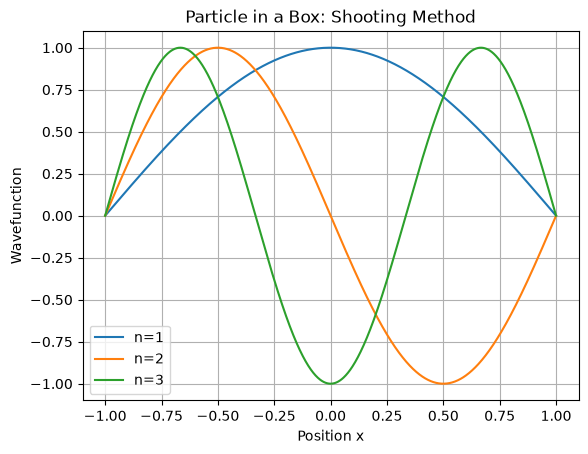

In [3]:

import numpy as np
import matplotlib.pyplot as plt

a = 1.0
steps = 1000
h = 2*a/steps

def shoot(E):
    # Start at the left boundary
    y = np.array([0.0, 1.0])

    def f(y):
        return np.array([y[1], -E*y[0]])

    for i in range(steps):
        k1 = f(y)
        k2 = f(y+h*k1/2)
        k3 = f(y+h*k2/2)
        k4 = f(y+h*k3)
        y += h*(k1+2*k2+2*k3+k4)/6

    return y[0]

def root(lo, hi):
    for _ in range(50):
        mid = (lo+hi)/2
        if shoot(lo)*shoot(mid) <= 0:
            hi = mid
        else:
            lo = mid
    return (lo+hi)/2

print("n   Analytical   Shooting")
for n in range(1, 4):
    exact = n**2*np.pi**2/(4*a**2)
    lo = exact*0.8
    hi = exact*1.2
    numerical = root(lo, hi)
    print(n, round(exact, 5), round(numerical, 5))

# Plot the shooting wavefunctions
x = np.linspace(-a, a, 1000)

for n in range(1, 4):
    E = n**2*np.pi**2/(4*a**2)
    y = np.sin(n*np.pi*(x+a)/(2*a))
    y /= np.sqrt(np.trapezoid(y**2, x))
    plt.plot(x, y, label=f"n={n}")

plt.xlabel("Position x")
plt.ylabel("Wavefunction")
plt.title("Particle in a Box: Shooting Method")
plt.legend()
plt.grid()
plt.show()
